<a href="https://colab.research.google.com/github/srazar/pad-flatness-analysis/blob/main/Pad_Flatness_Check.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Object; Generate data for a ficticious flatness measurements with random numbers
#Import libraries to allow builing excel like tables
#numpy will build arrays and padas will build tables like excel
import numpy as np
import pandas as pd

#Generate random data, we want consistency so the data is same in every run, to accomplish that a fixed seed number is defined
rng=np.random.default_rng(seed=1)
n_pads, n_points=20,25
#n_pads is number of pads(20)
#n_points is number of points(25)
#fill a 20x25 grid with deviations around 0 mm (normal distribution, spread 0.2mm)
data=rng.normal(loc=0.0, scale=0.2, size=(n_pads, n_points))
#Critical zones 1 and 2 have tighter requirements so give it smaller spread(0.05mm)
zone_cols=[3,7,9,11,13,14,15,18,19,21]
for p in zone_cols:
    data[:,p-1]=rng.normal(loc=0.0, scale=0.05, size=(n_pads))
#Turn the grid into a labeled table: columns P1...P25 rows pad_1...Pad_20
df=pd.DataFrame(data, columns=[f'P{i}' for i in range(1,n_points+1)])
df.index=[f"Pad_{i}" for i in range(1,n_pads+1)]

#save as csv
df.to_csv('pad_flatness.csv')
#show the first 5 rows, rounded as a check
df.round(3).head()

,P1,P2,P3,P4,P5,P6,P7,P8,P9,P10,...,P16,P17,P18,P19,P20,P21,P22,P23,P24,P25
Pad_1,0.069,0.164,-0.069,-0.261,0.181,0.089,0.047,0.116,0.001,0.059,...,0.120,0.008,0.020,-0.012,-0.051,-0.047,-0.055,0.259,0.201,-0.542
Pad_2,-0.378,-0.035,0.109,0.043,0.043,0.424,0.028,-0.076,0.049,0.129,...,-0.245,-0.137,0.030,-0.106,-0.020,0.027,0.007,-0.101,0.119,0.178
Pad_3,0.064,-0.164,-0.069,-0.100,0.176,-0.214,-0.080,-0.004,-0.048,-0.063,...,-0.093,0.047,0.001,0.009,0.051,-0.055,-0.060,-0.162,0.150,0.051
Pad_4,0.179,-0.069,-0.054,-0.022,-0.089,0.155,0.077,-0.326,0.038,0.177,...,0.175,0.051,0.056,-0.037,0.211,0.074,-0.028,0.007,-0.285,0.067
Pad_5,-0.130,0.172,-0.060,0.134,0.244,0.077,0.115,-0.303,-0.004,-0.022,...,0.003,-0.143,-0.036,-0.104,0.133,0.013,-0.305,-0.493,0.123,0.510


In [ ]:
#Read the file generated above
#index_col=0 tells pandas the first column hold the pad names
df=pd.read_csv('pad_flatness.csv', index_col=0)
# Spec definition, kept in one place so its easy to change later
zone1=["P3","P7","P9","P11","P13"]
zone2=["P14","P15","P18","P19","P21"]
OVERALL, ZONE=0.5, 0.1

In [19]:
#pass fail criteria use abosulute abs() to keep difference positive
#.all(axis=1)="every point in this row passes" -> on True/False per pad
overall_ok=(df.abs() <=OVERALL).all(axis=1) #all 25 points within +/-0.5
zone1_ok=(df[zone1].abs() <=ZONE).all(axis=1) #ONLY ZONE 1 COLUMNS, +/-0.1
zone2_ok=(df[zone2].abs() <= ZONE).all(axis=1) #ONLY  ZONE2 COLUMNS, +/-0.1

#NOW we will put three checks side by side; pad passes only if all three are True
report=pd.DataFrame({"Overall":overall_ok, "Zone1":zone1_ok, "Zone2":zone2_ok})
report["PASS"]=report.all(axis=1)

#Average of True/flase=Fraction of True=pass rate
print("Pass rate:", report["PASS"].mean())
report  #show the full pass/fail table

Pass rate: 0.65


,Overall,Zone1,Zone2,PASS
Pad_1,False,True,True,False
Pad_2,True,False,False,False
Pad_3,True,True,True,True
Pad_4,True,True,True,True
Pad_5,False,False,False,False
Pad_6,True,True,True,True
Pad_7,True,True,True,True
Pad_8,True,False,False,False
Pad_9,True,True,True,True
Pad_10,True,True,False,False


<function matplotlib.pyplot.show(close=None, block=None)>

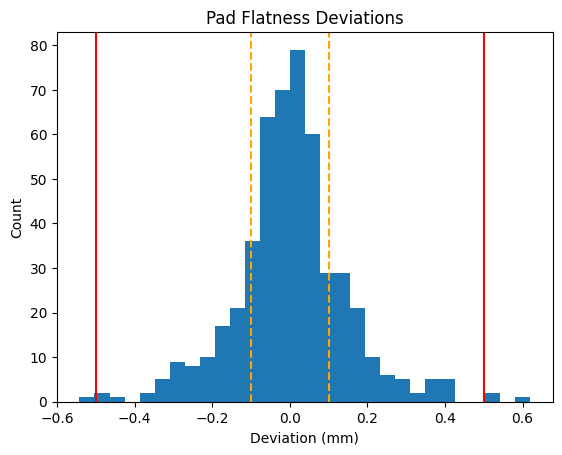

In [22]:
#Generate histogram of the results, for that we need matplotlib.pyplot library
import matplotlib.pyplot as plt
plt.hist(df.values.flatten(),bins=30) #all 500 readings 20x25 in one histogram
#Draw the spec lines: red=overall +/- 0.5, orange dashed=zone +/- 0.1
for x in (-OVERALL, OVERALL):plt.axvline(x, color="red")
for x in (-ZONE, ZONE):plt.axvline(x, color="orange", linestyle="dashed")

plt.xlabel("Deviation (mm)");plt.ylabel("Count");plt.title("Pad Flatness Deviations")
plt.show